# 05 | Model Explainability

## Objective

Understand how the selected Logistic Regression model uses
first-purchase customer characteristics to predict the
likelihood of a repeat purchase within 60 days.

## Analysis Scope

1. Inspect the saved model and preprocessing pipeline.
2. Examine Logistic Regression coefficients.
3. Identify important predictors and their direction of influence.
4. Apply SHAP for customer-level explanations.
5. Summarise findings, limitations and implications.

## Model

Unweighted Logistic Regression using nine first-purchase features.

The model is retained as a reproducible baseline.
Explainability findings describe model behaviour and should
not be interpreted as causal effects.

In [3]:
# Load the saved Logistic Regression model

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

# Locate the project directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define saved model location
model_path = (
    project_root
    / "models"
    / "repeat_purchase_logistic_regression.joblib"
)

# Confirm the model exists
print("Saved model exists:", model_path.is_file())

# Load the trained pipeline
selected_model = joblib.load(model_path)

# Access the preprocessing and classification components
preprocessor = selected_model.named_steps["preprocessor"]
classifier = selected_model.named_steps["classifier"]

# Display model information
print("\nModel type:", type(classifier).__name__)

print(
    "Original model features:",
    len(selected_model.feature_names_in_)
)

print(
    "Transformed features:",
    len(preprocessor.get_feature_names_out())
)

print(
    "Model coefficients:",
    classifier.coef_.shape
)

Saved model exists: True

Model type: LogisticRegression
Original model features: 9
Transformed features: 102
Model coefficients: (1, 102)


In [4]:
#  Extract Logistic Regression coefficients

# Retrieve transformed feature names
transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

# Retrieve fitted model coefficients
model_coefficients = classifier.coef_[0]

# Match feature names to coefficients
coefficient_summary = pd.DataFrame({
    "feature": transformed_feature_names,
    "coefficient": model_coefficients
})

# Calculate absolute coefficient magnitude
coefficient_summary["absolute_coefficient"] = (
    coefficient_summary["coefficient"].abs()
)

# Rank transformed features by coefficient magnitude
coefficient_summary = (
    coefficient_summary
    .sort_values("absolute_coefficient", ascending=False)
    .reset_index(drop=True)
)

print("Total transformed features:", len(coefficient_summary))

print("\nTop 10 positive coefficients:")
display(
    coefficient_summary
    .sort_values("coefficient", ascending=False)
    .head(10)
)

print("\nTop 10 negative coefficients:")
display(
    coefficient_summary
    .sort_values("coefficient", ascending=True)
    .head(10)
)

Total transformed features: 102

Top 10 positive coefficients:


,feature,coefficient,absolute_coefficient
0,categorical__first_order_primary_category_elet...,1.570696,1.570696
1,categorical__first_order_primary_category_fash...,1.151576,1.151576
2,categorical__first_order_primary_category_agro...,1.031662,1.031662
3,categorical__first_order_primary_category_move...,1.010483,1.010483
4,categorical__first_order_primary_category_cama...,0.996195,0.996195
5,categorical__first_order_primary_category_artes,0.983356,0.983356
7,categorical__customer_state_AC,0.907188,0.907188
10,categorical__first_order_primary_category_fash...,0.822363,0.822363
17,categorical__first_order_primary_category_mark...,0.645428,0.645428
21,categorical__first_order_primary_category_move...,0.570849,0.570849



Top 10 negative coefficients:


,feature,coefficient,absolute_coefficient
6,categorical__customer_state_SC,-0.945785,0.945785
8,categorical__first_order_primary_category_cool...,-0.880102,0.880102
9,categorical__customer_state_PI,-0.844547,0.844547
11,categorical__first_order_primary_category_tele...,-0.785882,0.785882
12,categorical__first_order_primary_category_livr...,-0.749668,0.749668
13,categorical__first_order_primary_category_move...,-0.695662,0.695662
14,categorical__first_order_primary_category_auto...,-0.685966,0.685966
15,categorical__customer_state_RN,-0.672493,0.672493
16,categorical__first_order_primary_category_clim...,-0.656459,0.656459
18,categorical__first_order_primary_category_mala...,-0.599599,0.599599


In [5]:
# Check the distribution of model coefficient directions

print(
    "Positive coefficients:",
    (coefficient_summary["coefficient"] > 0).sum()
)

print(
    "Negative coefficients:",
    (coefficient_summary["coefficient"] < 0).sum()
)

print(
    "Zero coefficients:",
    (coefficient_summary["coefficient"] == 0).sum()
)

print(
    "\nLargest positive coefficient:",
    coefficient_summary["coefficient"].max()
)

print(
    "Largest negative coefficient:",
    coefficient_summary["coefficient"].min()
)

Positive coefficients: 35
Negative coefficients: 67
Zero coefficients: 0

Largest positive coefficient: 1.5706963836507242
Largest negative coefficient: -0.9457854875457746


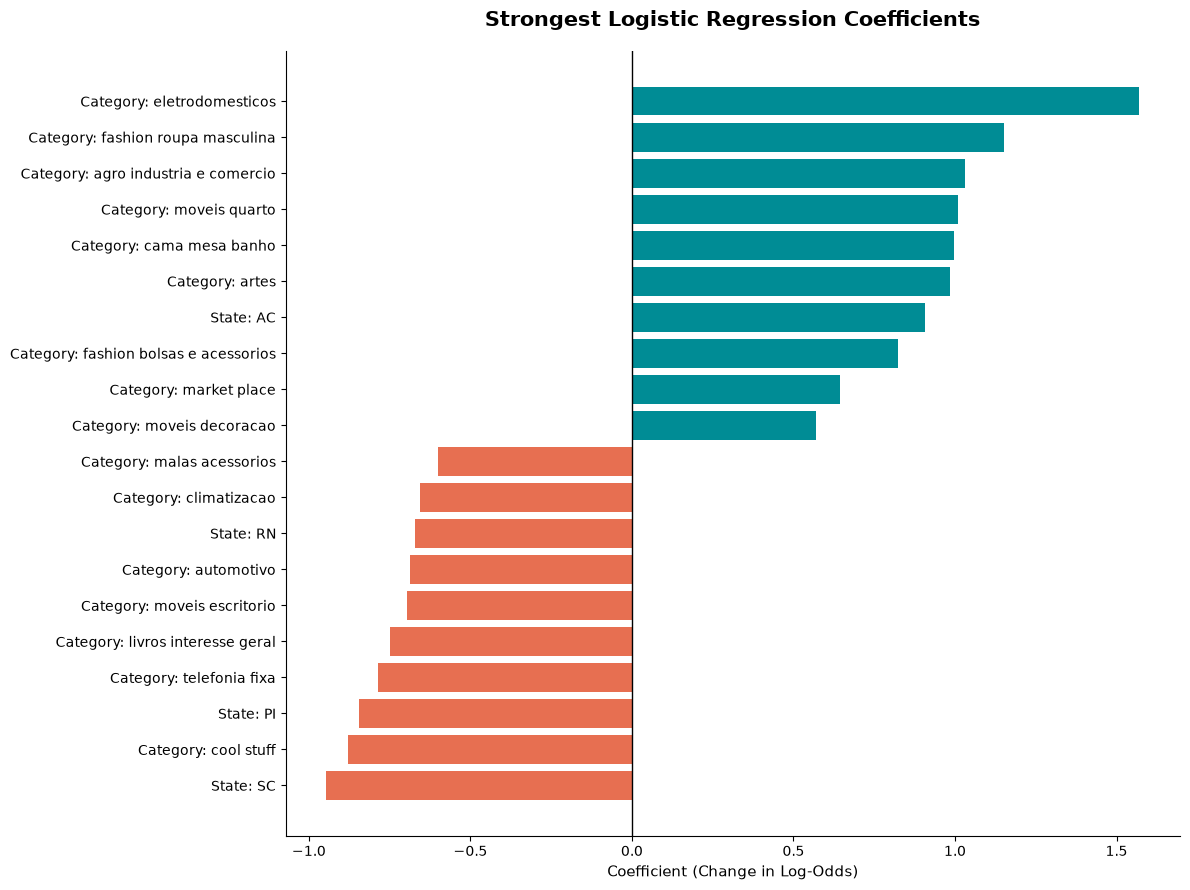

In [6]:
# Visualise the strongest positive and negative coefficients

import matplotlib.pyplot as plt
import numpy as np

# Select the strongest positive coefficients
top_positive = (
    coefficient_summary
    .nlargest(10, "coefficient")
)

# Select the strongest negative coefficients
top_negative = (
    coefficient_summary
    .nsmallest(10, "coefficient")
)

# Combine both groups
top_coefficients = pd.concat([
    top_negative,
    top_positive
])

# Sort for horizontal visualisation
top_coefficients = top_coefficients.sort_values(
    "coefficient"
)

# Create readable feature labels
feature_labels = (
    top_coefficients["feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numerical__", "", regex=False)
    .str.replace("first_order_primary_category_", "Category: ", regex=False)
    .str.replace("customer_state_", "State: ", regex=False)
    .str.replace("_", " ", regex=False)
)

# Colour coefficients by direction
bar_colors = np.where(
    top_coefficients["coefficient"] > 0,
    "#008C95",
    "#E76F51"
)

# Create chart
fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    feature_labels,
    top_coefficients["coefficient"],
    color=bar_colors
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Strongest Logistic Regression Coefficients",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Coefficient (Change in Log-Odds)",
    fontsize=11
)

ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [7]:
# Load customer data for model explanations

feature_path = (
    project_root
    / "data"
    / "processed"
    / "customer_features.pkl"
)

# Load the saved feature dataset
customer_features = pd.read_pickle(feature_path)

# Use only predictors expected by the saved model
model_features = list(selected_model.feature_names_in_)

# Select records with complete model features
explanation_features = customer_features.loc[
    customer_features[model_features].notna().all(axis=1),
    model_features
].copy()

# Inspect the explanation population
print("Feature dataset shape:", customer_features.shape)

print("Customers available for explanation:", len(explanation_features))

print("Original model features:", len(model_features))

print(
    "Missing values:",
    int(explanation_features.isna().sum().sum())
)

Feature dataset shape: (78100, 29)
Customers available for explanation: 76197
Original model features: 9
Missing values: 0


In [8]:
# Prepare a training-period reference dataset for SHAP

# Recreate the original chronological training boundaries
train_end = pd.Timestamp("2017-06-30 23:59:59")
validation_start = pd.Timestamp("2017-10-01")

observation_window = pd.Timedelta(days=90)

# Identify training-period customers
training_mask = (
    (customer_features["order_purchase_timestamp"] <= train_end)
    & (
        customer_features["order_purchase_timestamp"]
        + observation_window < validation_start
    )
)

# Restrict to complete model features
complete_mask = customer_features[
    model_features
].notna().all(axis=1)

# Prepare training-period explanation data
X_explain_train = customer_features.loc[
    training_mask & complete_mask,
    model_features
].copy()

print("Training-period explanation customers:", len(X_explain_train))

print(
    "Missing feature values:",
    int(X_explain_train.isna().sum().sum())
)

print(
    "Original model features:",
    X_explain_train.shape[1]
)

Training-period explanation customers: 14051
Missing feature values: 0
Original model features: 9


In [9]:
#  Transform training-period features for SHAP

# Apply the saved model's fitted preprocessing
X_train_transformed = preprocessor.transform(
    X_explain_train
)

# Retrieve the transformed feature names
transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

# Convert to a dense array if required
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

# Create a labelled dataframe
X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=transformed_feature_names,
    index=X_explain_train.index
)

# Select a reproducible background sample
shap_background = X_train_shap.sample(
    n=min(500, len(X_train_shap)),
    random_state=42
)

# Verify the prepared data
print("Transformed training data:", X_train_shap.shape)
print("SHAP background sample:", shap_background.shape)
print("Missing values:", int(shap_background.isna().sum().sum()))

Transformed training data: (14051, 102)
SHAP background sample: (500, 102)
Missing values: 0


In [10]:
# Calculate linear feature contributions without SHAP

# Select a reproducible explanation sample
X_shap_sample = X_train_shap.sample(
    n=min(1000, len(X_train_shap)),
    random_state=42
)

# Calculate mean feature values from our training background
background_mean = shap_background.mean(axis=0)

# Retrieve fitted Logistic Regression coefficients
coefficients = classifier.coef_[0]

# Calculate feature contributions in log-odds units
linear_contributions = (
    X_shap_sample - background_mean
).mul(coefficients, axis=1)

# Calculate the reference prediction in log-odds
base_log_odds = (
    classifier.intercept_[0]
    + np.dot(background_mean, coefficients)
)

# Reconstruct the model's predictions
reconstructed_log_odds = (
    base_log_odds
    + linear_contributions.sum(axis=1)
)

actual_log_odds = classifier.decision_function(
    X_shap_sample
)

# Validate the calculations
print("Explanation sample:", X_shap_sample.shape)
print("Contribution matrix:", linear_contributions.shape)

print(
    "Maximum reconstruction error:",
    np.max(
        np.abs(
            reconstructed_log_odds - actual_log_odds
        )
    )
)

print(
    "Missing contributions:",
    int(linear_contributions.isna().sum().sum())
)

Explanation sample: (1000, 102)
Contribution matrix: (1000, 102)
Maximum reconstruction error: 1.3322676295501878e-15
Missing contributions: 0


c:\Users\oades\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [11]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
# Aggregate contributions into the nine original features

# Use the fitted preprocessor to identify transformed feature groups
original_feature_names = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "first_order_item_count",
    "first_order_product_count",
    "first_order_item_value",
    "first_order_freight_value",
    "first_order_primary_category"
]

# Build one contribution per original feature for each customer
grouped_contributions = pd.DataFrame(
    index=linear_contributions.index
)

for feature in original_feature_names:

    if feature in [
        "customer_state",
        "first_order_primary_category"
    ]:
        matching_columns = [
            col for col in linear_contributions.columns
            if col.startswith(f"categorical__{feature}_")
        ]
    else:
        matching_columns = [
            f"numerical__{feature}"
        ]

    grouped_contributions[feature] = (
        linear_contributions[matching_columns].sum(axis=1)
    )

# Calculate mean absolute contribution per original feature
global_importance = (
    grouped_contributions
    .abs()
    .mean()
    .sort_values(ascending=False)
    .to_frame("mean_absolute_contribution")
)

print("Original feature groups:", len(global_importance))

print(
    "Maximum grouping reconstruction error:",
    np.abs(
        grouped_contributions.sum(axis=1)
        - linear_contributions.sum(axis=1)
    ).max()
)

display(global_importance.round(4))

Original feature groups: 9
Maximum grouping reconstruction error: 1.7763568394002505e-15


,mean_absolute_contribution
first_order_primary_category,0.4766
customer_state,0.1147
purchase_day_of_week,0.0958
first_order_item_count,0.0425
first_order_product_count,0.0316
first_order_item_value,0.0183
purchase_month,0.0163
first_order_freight_value,0.0083
purchase_hour,0.0045


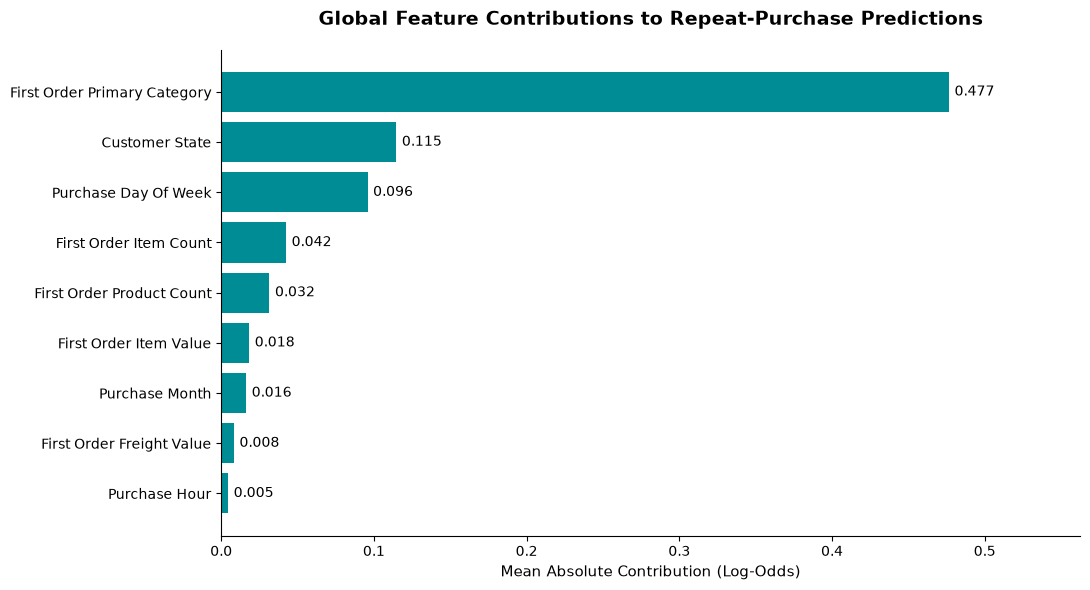

In [13]:
# Step 9: Visualise global model feature contributions

import matplotlib.pyplot as plt

# Sort features for a horizontal bar chart
plot_data = global_importance.sort_values(
    "mean_absolute_contribution",
    ascending=True
)

# Make labels readable
labels = [
    name.replace("_", " ").title()
    for name in plot_data.index
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    labels,
    plot_data["mean_absolute_contribution"],
    color="#008C95"
)

# Display values beside the bars
ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4
)

ax.set_title(
    "Global Feature Contributions to Repeat-Purchase Predictions",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Mean Absolute Contribution (Log-Odds)",
    fontsize=11
)

ax.set_ylabel("")
ax.set_xlim(
    0,
    plot_data["mean_absolute_contribution"].max() * 1.18
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
# Explain an individual customer prediction

from scipy.special import expit

# Select the first customer in our explanation sample
customer_index = X_shap_sample.index[0]

# Retrieve the customer's original features
customer_features_row = X_explain_train.loc[
    [customer_index]
]

# Calculate the model's predicted probability
predicted_probability = selected_model.predict_proba(
    customer_features_row
)[0, 1]

# Retrieve this customer's grouped contributions
customer_contributions = grouped_contributions.loc[
    customer_index
].sort_values()

# Reconstruct the customer's prediction
customer_log_odds = (
    base_log_odds
    + customer_contributions.sum()
)

reconstructed_probability = expit(customer_log_odds)

print("Customer index:", customer_index)

print(
    "Model predicted probability:",
    f"{predicted_probability:.4%}"
)

print(
    "Reconstructed probability:",
    f"{reconstructed_probability:.4%}"
)

print(
    "Probability reconstruction error:",
    abs(predicted_probability - reconstructed_probability)
)

print("\nIndividual feature contributions:")

display(
    customer_contributions.to_frame(
        "log_odds_contribution"
    ).round(4)
)

Customer index: 17993
Model predicted probability: 1.0480%
Reconstructed probability: 1.0480%
Probability reconstruction error: 0.0

Individual feature contributions:


,log_odds_contribution
first_order_primary_category,-0.5240
first_order_item_count,-0.0255
purchase_month,-0.0253
first_order_product_count,-0.0159
customer_state,-0.0061
first_order_freight_value,0.0073
purchase_hour,0.0124
purchase_day_of_week,0.0168
first_order_item_value,0.0184


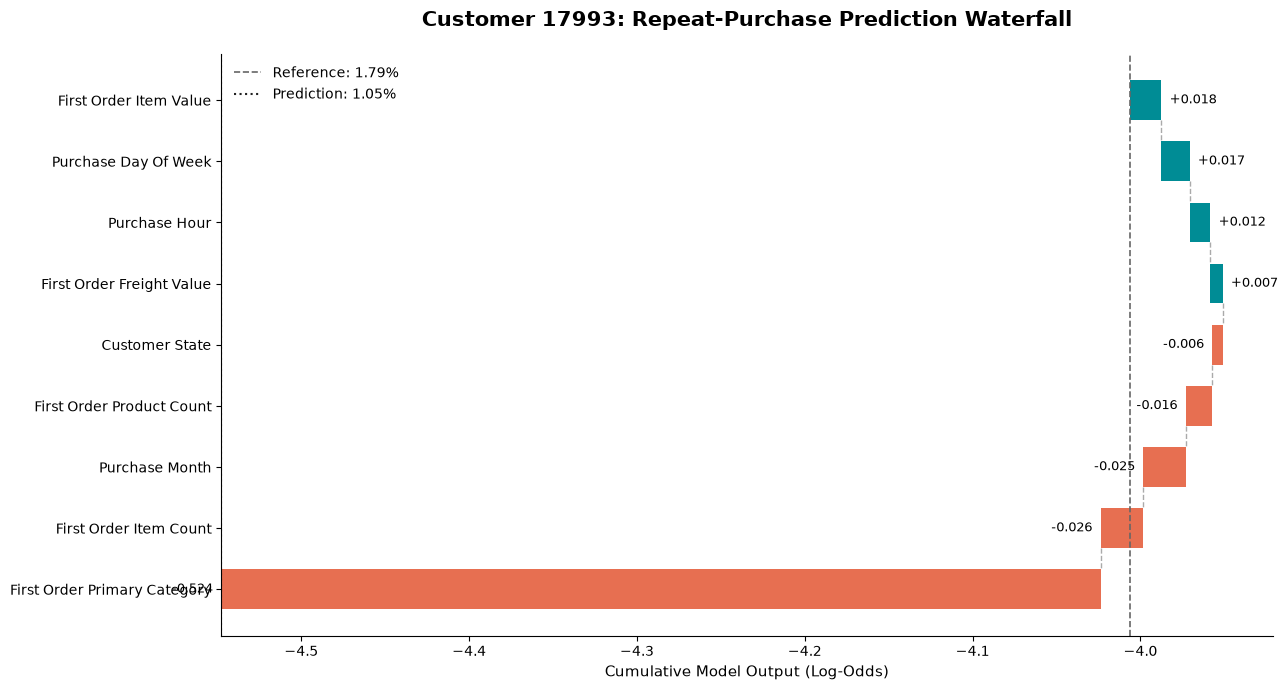

Model predicted probability: 1.0480%
Waterfall reconstructed probability: 1.0480%
Reconstruction error: 0.0


In [17]:
#  Visualise individual prediction using a waterfall chart

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import expit

# Retrieve the customer's feature contributions
contributions = customer_contributions.sort_values(
    ascending=False
)

# Create readable labels
labels = [
    feature.replace("_", " ").title()
    for feature in contributions.index
]

values = contributions.to_numpy()

# Calculate cumulative log-odds
starting_log_odds = base_log_odds

cumulative_values = (
    starting_log_odds
    + np.cumsum(values)
)

previous_values = np.concatenate([
    [starting_log_odds],
    cumulative_values[:-1]
])

# Calculate waterfall bar positions
bar_starts = np.minimum(
    previous_values,
    cumulative_values
)

bar_widths = np.abs(values)

# Assign colours
colors = [
    "#008C95" if value > 0 else "#E76F51"
    for value in values
]

# Create the figure
fig, ax = plt.subplots(figsize=(13, 7))

y_positions = np.arange(len(values))

ax.barh(
    y_positions,
    bar_widths,
    left=bar_starts,
    color=colors,
    height=0.65
)

# Connect the cumulative contributions
for i in range(len(values) - 1):
    ax.plot(
        [
            cumulative_values[i],
            cumulative_values[i]
        ],
        [y_positions[i] + 0.325,
         y_positions[i + 1] - 0.325],
        color="#AAAAAA",
        linestyle="--",
        linewidth=1
    )

# Display feature labels
ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.invert_yaxis()

# Label the contribution values
for i, value in enumerate(values):

    endpoint = cumulative_values[i]

    ax.annotate(
        f"{value:+.3f}",
        xy=(endpoint, y_positions[i]),
        xytext=(
            6 if value >= 0 else -6,
            0
        ),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

# Reference and predicted probabilities
reference_probability = expit(starting_log_odds)
final_probability = expit(cumulative_values[-1])

ax.axvline(
    starting_log_odds,
    color="#666666",
    linestyle="--",
    linewidth=1.2,
    label=f"Reference: {reference_probability:.2%}"
)

ax.axvline(
    cumulative_values[-1],
    color="#222222",
    linestyle=":",
    linewidth=1.5,
    label=f"Prediction: {final_probability:.2%}"
)

# Chart styling
ax.set_title(
    f"Customer {customer_index}: Repeat-Purchase Prediction Waterfall",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Cumulative Model Output (Log-Odds)",
    fontsize=11
)

ax.set_ylabel("")

ax.legend(
    loc="upper left",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Validate the final probability
print(
    "Model predicted probability:",
    f"{predicted_probability:.4%}"
)

print(
    "Waterfall reconstructed probability:",
    f"{final_probability:.4%}"
)

print(
    "Reconstruction error:",
    abs(predicted_probability - final_probability)
)

In [18]:
# Compare low, medium and high propensity customers

# Retrieve original features for our existing explanation sample
sample_customers = X_explain_train.loc[
    X_shap_sample.index
].copy()

# Generate probabilities using our saved model
sample_customers["predicted_probability"] = (
    selected_model.predict_proba(
        sample_customers[model_features]
    )[:, 1]
)

# Sort customers by predicted probability
ranked_sample = sample_customers.sort_values(
    "predicted_probability"
)

# Select representative customers
representative_indices = {
    "Low propensity": ranked_sample.index[0],
    "Medium propensity": ranked_sample.index[
        len(ranked_sample) // 2
    ],
    "High propensity": ranked_sample.index[-1]
}

# Summarise predictions and feature contributions
comparison_rows = []

for segment, idx in representative_indices.items():

    contributions = grouped_contributions.loc[idx]

    comparison_rows.append({
        "Segment": segment,
        "Customer Index": idx,
        "Predicted Probability (%)": round(
            sample_customers.loc[
                idx, "predicted_probability"
            ] * 100, 4
        ),
        "Strongest Positive Feature": (
            contributions.idxmax()
        ),
        "Strongest Negative Feature": (
            contributions.idxmin()
        )
    })

customer_comparison = pd.DataFrame(comparison_rows)

print("Representative Customer Prediction Comparison")
print("-" * 55)

display(customer_comparison)

Representative Customer Prediction Comparison
-------------------------------------------------------


,Segment,Customer Index,Predicted Probability (%),Strongest Positive Feature,Strongest Negative Feature
0,Low propensity,38369,0.2686,purchase_month,customer_state
1,Medium propensity,76663,1.5967,customer_state,first_order_primary_category
2,High propensity,1955,17.9950,first_order_product_count,first_order_freight_value


In [19]:
# Validate representative customer explanations

from scipy.special import expit

validation_rows = []

for segment, idx in representative_indices.items():

    # Original model prediction
    original_probability = selected_model.predict_proba(
        X_explain_train.loc[[idx], model_features]
    )[0, 1]

    # Reconstruct prediction from grouped contributions
    reconstructed_log_odds = (
        base_log_odds
        + grouped_contributions.loc[idx].sum()
    )

    reconstructed_probability = expit(
        reconstructed_log_odds
    )

    validation_rows.append({
        "segment": segment,
        "model_probability": original_probability,
        "reconstructed_probability": reconstructed_probability,
        "absolute_error": abs(
            original_probability - reconstructed_probability
        )
    })

explanation_validation = pd.DataFrame(validation_rows)

print("Representative Customer Explanation Validation")
display(explanation_validation.round(10))

print(
    "Maximum reconstruction error:",
    explanation_validation["absolute_error"].max()
)

Representative Customer Explanation Validation


,segment,model_probability,reconstructed_probability,absolute_error
0,Low propensity,0.002686,0.002686,0.0
1,Medium propensity,0.015967,0.015967,0.0
2,High propensity,0.179950,0.179950,0.0


Maximum reconstruction error: 1.3877787807814457e-16


## Model Explainability: Findings and Conclusions

### Objective

Understand how the selected Logistic Regression model uses first-purchase customer characteristics to generate 60-day repeat-purchase predictions.

### Methodology

The saved model contains nine original predictors transformed into 102 numerical and encoded features.

Model explanations were calculated using a linear feature-contribution approach with a 500-customer training-background sample.

Global explanations were evaluated across 1,000 sampled training-period customers.

Because the SHAP library's compiled component was blocked by the local Windows application-control policy, feature contributions were calculated directly using Logistic Regression coefficients.

These calculations use an independent-feature reference assumption and explain changes in model log-odds rather than direct percentage-point changes in repeat-purchase probability.

### Key Findings

**Global feature contributions**

First-order primary product category had the largest mean absolute contribution (0.4766 log-odds), followed by customer state (0.1147) and purchase day of week (0.0958).

**Individual explanations**

Customers with different predicted repeat-purchase probabilities showed different combinations of positive and negative feature contributions.

The three illustrative customers had predicted probabilities of 0.2686%, 1.5967% and 17.9950%.

**Explanation validation**

The calculated contributions reconstructed the original model predictions to numerical precision, with a maximum error of approximately 1.39 × 10⁻¹⁶ across the three representative examples.

### Limitations

- Feature contributions describe model behaviour, not causal effects.
- Global rankings depend on the selected explanation sample and background distribution.
- Correlations and dependencies between features are not explicitly modelled in the independent-feature contribution approach.
- Large coefficients for infrequent categories may be unstable.
- The existing model has limited discrimination and exhibits probability overestimation on the reserved holdout dataset.
- Explanation consistency does not establish predictive accuracy or reliability.

### Conclusion

The explainability analysis provides a transparent view of how the baseline Logistic Regression model generates customer-level predictions.

Product category, customer geography and purchase timing are important components of the model's decision function.

Future development should assess feature stability and predictive improvement using appropriately separated development data, while preserving the existing holdout results as the independent baseline evaluation.